<a href="https://colab.research.google.com/github/LuisDavid0460/ProbabilidadYEstadistica/blob/main/Unidad6/PracticaFinalProbabilidadYEstadistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final: Análisis Estadístico de Datos COVID-19 en Python

### **Materia:** Probabilidad y Estadística
### **Grupo:** 2Y
### **Periodo del semestre:** Agosto a Diciembre del 2026
### **Fecha de entrega:** 26/11/2026
### **Integrantes del equipo:**
#### Hernández Gómez Luis David
#### Diaz Renteria Luis Fernando
#### Márquez Herrera Diego Eduardo
#### Neri Zadquiel Jaramillo Martínez

### **Docente:** Rodriguez Rivas Jose Gabriel

In [1]:
from google.colab import drive
import pandas as pd

# 1. Conectamos los datos desde google drive para ver que nesesitamos
drive.mount('/content/drive')

ruta = "/content/drive/MyDrive/covid2020-2021-codificado.csv"

df = pd.read_csv(ruta, encoding="utf-8", low_memory=False)
print(f"Total de registros cargados: {len(df):,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total de registros cargados: 12,634,194


Número de casos positivos es : 1774708
Número de casos negativos: 5853547
Número de casos pendientes: 5005939

Número d pacientes ambulatorios: 11543303
Número de pacientes hospitalizados: 1090891

Número de pacientes embarazadas: 122583
Número de pacientes indígenas: 35240





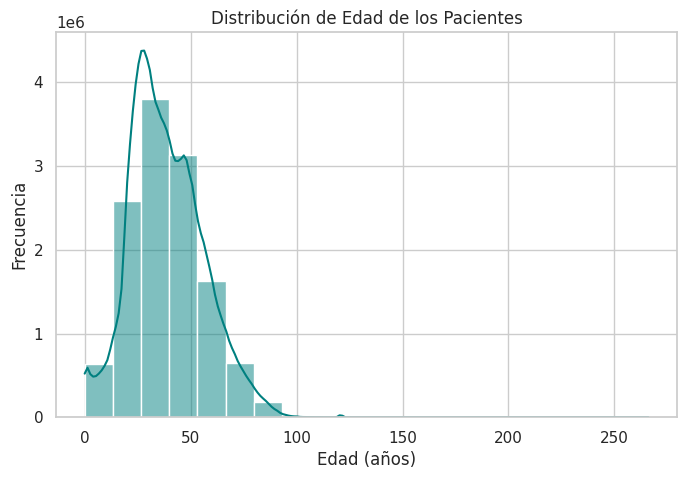

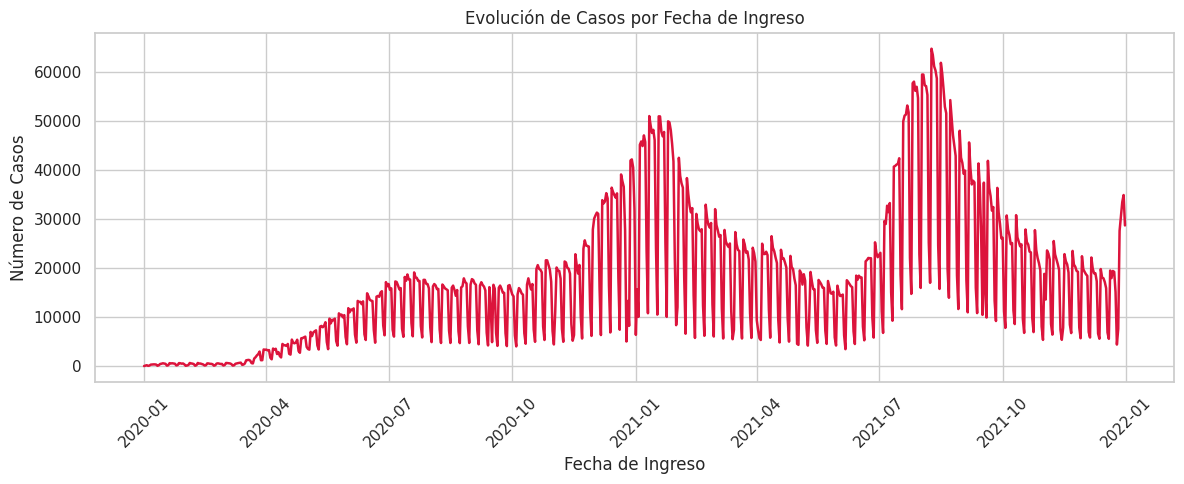

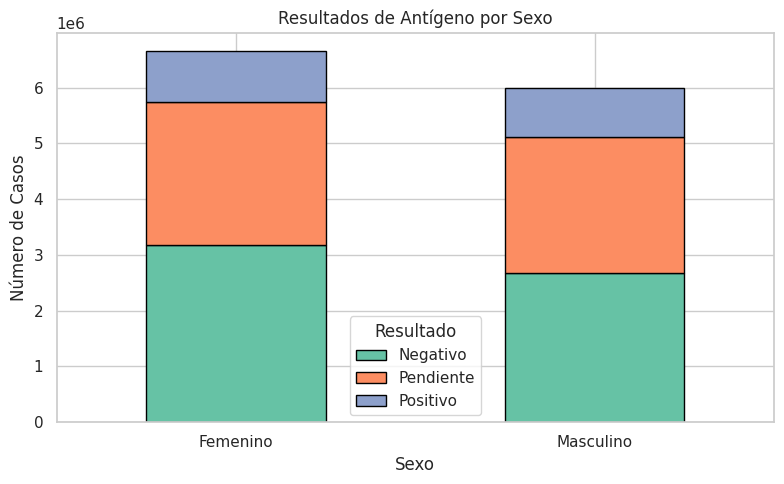

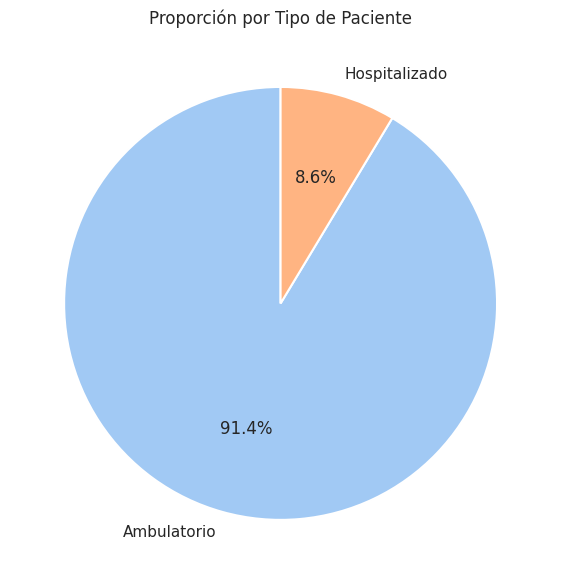

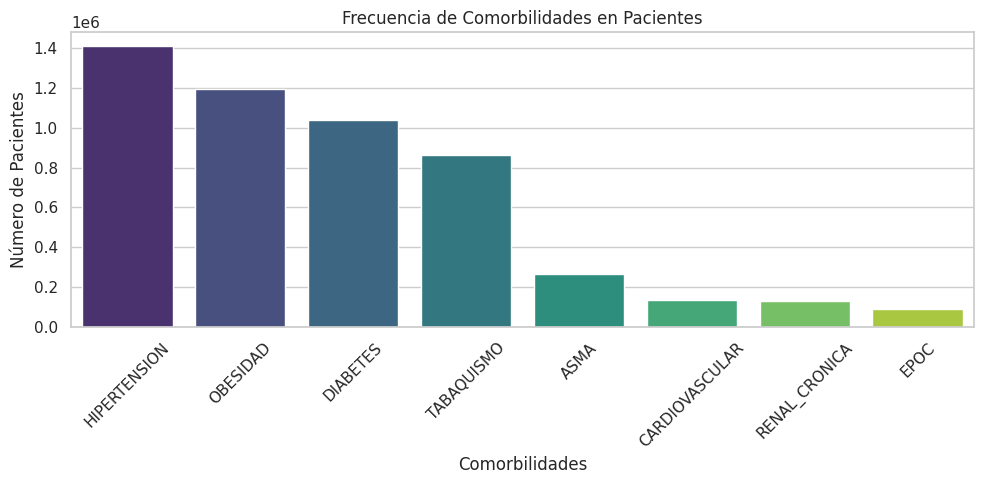

Total general de registros: 12634194

--- PROBABILIDAD SIMPLE POR COMORBILIDAD ---
                Casos_Con_Comorbilidad  Probabilidad_Simple  Porcentaje (%)
HIPERTENSION                   1407779               0.1114           11.14
OBESIDAD                       1193021               0.0944            9.44
DIABETES                       1038459               0.0822            8.22
TABAQUISMO                      865162               0.0685            6.85
ASMA                            263855               0.0209            2.09
CARDIOVASCULAR                  134410               0.0106            1.06
RENAL_CRONICA                   129874               0.0103            1.03
EPOC                             92446               0.0073            0.73
--- PROBABILIDAD CONDICIONAL POR ESTADO (Proporción de 0 a 1) ---
                      DIABETES  HIPERTENSION  OBESIDAD    EPOC    ASMA  \
ENTIDAD_NAC                                                              
99                 

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statistics import *
import math
sns.set_theme(style="whitegrid")

##Aqui vemos como dividir los casos de positivos, negativos y pendientes
conteo_casos = df['RESULTADO_ANTIGENO'].value_counts()

##Y aqui si esos casos son de cada uno que un contador le sume mas 1 para tneer eol conteo de cada uno de todos los archivos
positivos = (df['RESULTADO_ANTIGENO'] == 'Positivo').sum()
negativos = (df['RESULTADO_ANTIGENO'] == 'Negativo').sum()
pendientes = (df['RESULTADO_ANTIGENO'] == 'Pendiente').sum()

print(f"Número de casos positivos es : {positivos}")
print(f"Número de casos negativos: {negativos}")
print(f"Número de casos pendientes: {pendientes}")

##Aqui vemos los tipos de pacientes y los ponemos los contadores
tipo_paciente = df['TIPO_PACIENTE'].value_counts()

##Aqui anotamos los numoeros de pacientes de cada uno
Ambulatorio=(df['TIPO_PACIENTE'] == 'Ambulatorio').sum()
print(f"\nNúmero d pacientes ambulatorios: {Ambulatorio}")
Hospitalizado=(df['TIPO_PACIENTE'] == 'Hospitalizado').sum()
print(f"Número de pacientes hospitalizados: {Hospitalizado}")


##Aqui lo que hacemos es contar la cantidad de opacientes que estan embarazadas y solo imprimir la cantidad que hay de embarazadas
embarazadas = (df['EMBARAZO'] == 'Si').sum()
print(f"\nNúmero de pacientes embarazadas: {embarazadas}")

##Aqui tenemos lo de los indigenas o miembros de pueblos originarios la cantidad y si losson cuantos
indigenas = (df['INDIGENA'] == 'Si').sum()
print(f"Número de pacientes indígenas: {indigenas}")

print("\n\n")

##Graficamos el hsitograma de la edad con la frecuencia de casos
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='EDAD', bins=20, kde=True, color='teal')
plt.title('Distribución de Edad de los Pacientes')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.show()

##Nos aseguramos de contaar correctamente las fechas de ingresos
df['FECHA_INGRESO'] = pd.to_datetime(df['FECHA_INGRESO'])
evolucion_fecha = df['FECHA_INGRESO'].value_counts().sort_index().reset_index()
evolucion_fecha.columns = ['Fecha', 'Casos']

plt.figure(figsize=(12, 5))
sns.lineplot(data=evolucion_fecha, x='Fecha', y='Casos', color='crimson', linewidth=1.8)
plt.title('Evolución de Casos por Fecha de Ingreso')
plt.xlabel('Fecha de Ingreso')
plt.ylabel('Número de Casos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Aqui iniciamos lo de diferenciar oor sexo los casos de pendiente,negativos o positivos por barras apiladas
tabla_sexo_res = pd.crosstab(df['SEXO'], df['RESULTADO_ANTIGENO'])
colores_sns = sns.color_palette('Set2', n_colors=len(tabla_sexo_res.columns))

ax = tabla_sexo_res.plot(kind='bar', stacked=True, figsize=(8, 5), color=colores_sns, edgecolor='black')
plt.title('Resultados de Antígeno por Sexo')
plt.xlabel('Sexo')
plt.ylabel('Número de Casos')
plt.xticks(rotation=0)
plt.legend(title='Resultado')
plt.tight_layout()
plt.show()

##Aqui iniciamos lo de diferenciar por tipops de pacientes para la grafica circular
conteo_tipo = df['TIPO_PACIENTE'].value_counts()
colores_pastel = sns.color_palette('pastel', n_colors=len(conteo_tipo))

plt.figure(figsize=(6, 6))
plt.pie(
    conteo_tipo.values,
    labels=conteo_tipo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_pastel,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Proporción por Tipo de Paciente')
plt.tight_layout()
plt.show()

##Aqui lo que hacemos es especificar lo que queremos para cada columna de la cormobilidad para todas estas y la cantidad de cassos que tieme cada una
##Asi poder hacer las graficas de barras separadas por cormobilidad
columnas_comorb = ['DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'INMUSUPR']
columnas_comorb = [col for col in columnas_comorb if col in df.columns]
conteo_comorb = (df[columnas_comorb] == 'Si').sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=conteo_comorb.index, y=conteo_comorb.values, hue=conteo_comorb.index, palette='viridis', legend=False)
plt.title('Frecuencia de Comorbilidades en Pacientes')
plt.xlabel('Comorbilidades')
plt.ylabel('Número de Pacientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##Aqui lo que hacemos es la cantidad e cada cormobilidad, el porcentaje de estooso y la probabilidad de tenr uno
comorbilidades_deseadas = ['DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC', 'ASMA', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO']
comorbilidades = [col for col in comorbilidades_deseadas if col in df.columns]
total_general = len(df)
total_por_comorb = (df[comorbilidades] == 'Si').sum()
prob_simple = total_por_comorb / total_general
tabla_prob_simple = pd.DataFrame({
    'Casos_Con_Comorbilidad': total_por_comorb,
    'Probabilidad_Simple': prob_simple.round(4),
    'Porcentaje (%)': (prob_simple * 100).round(2)
}).sort_values(by='Probabilidad_Simple', ascending=False)
print(f"Total general de registros: {total_general}\n")
print("--- PROBABILIDAD SIMPLE POR COMORBILIDAD ---")
print(tabla_prob_simple)

##Aqui sacamos el total por cada estado
total_por_estado = df.groupby('ENTIDAD_NAC').size()
##Aqui la cantidad de cormovilidad y de personas de cada esto de que cada paciente de ese estado tenga la cormobilidad
casos_estado_comorb = df.groupby('ENTIDAD_NAC')[comorbilidades].apply(lambda x: (x == 'Si').sum())
prob_condicional_estado = casos_estado_comorb.div(total_por_estado, axis=0)
print("--- PROBABILIDAD CONDICIONAL POR ESTADO (Proporción de 0 a 1) ---")
print(prob_condicional_estado.round(4))

print("\n--- PROBABILIDAD CONDICIONAL EN PORCENTAJE (%) ---")
print((prob_condicional_estado * 100).round(2))


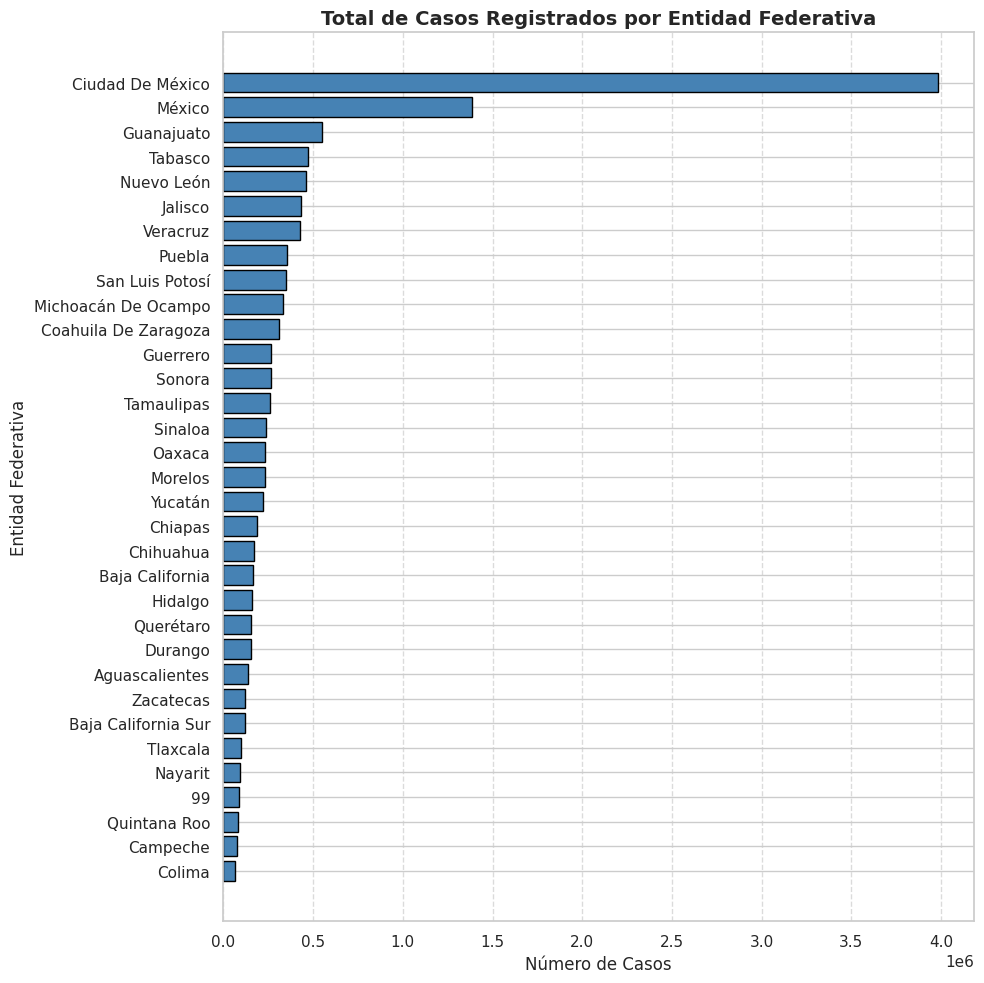

In [7]:
# Contamos los casos por entidad federativa y los ordenamos de menor a mayor para que arriba quede el mas alto de todos
conteo_estados = df['ENTIDAD_NAC'].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10, 10))
plt.barh(conteo_estados.index, conteo_estados.values, color='steelblue', edgecolor='black')
plt.title('Total de Casos Registrados por Entidad Federativa', fontsize=14, fontweight='bold')
plt.xlabel('Número de Casos')
plt.ylabel('Entidad Federativa')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- EJERCICIO DE DISTRIBUCIÓN NORMAL ---
Valor Z para 2000 casos: -0.5042
Valor Z para 3000 casos: 0.8964
Probabilidad de tener entre 2000 y 3000 casos: 0.5079 (50.79%)


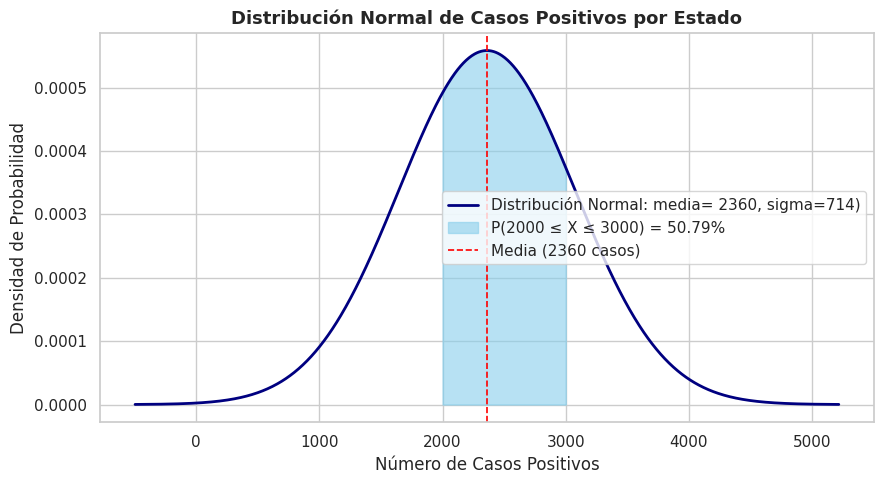

In [9]:
import numpy as np
from scipy.stats import norm

# Parametros de las especificaciones de la practica
media = 2360
desv_est = 714
limite_inf = 2000
limite_sup = 3000

# Calculo de probabilidad P(2000 <= X <= 3000)
prob_intervalo = norm.cdf(limite_sup, loc=media, scale=desv_est) - norm.cdf(limite_inf, loc=media, scale=desv_est)
z1 = (limite_inf - media) / desv_est
z2 = (limite_sup - media) / desv_est

print("--- EJERCICIO DE DISTRIBUCIÓN NORMAL ---")
print(f"Valor Z para {limite_inf} casos: {z1:.4f}")
print(f"Valor Z para {limite_sup} casos: {z2:.4f}")
print(f"Probabilidad de tener entre {limite_inf} y {limite_sup} casos: {prob_intervalo:.4f} ({prob_intervalo*100:.2f}%)")

# Grafica de la campana de Gauss con el area sombreada
x = np.linspace(media - 4*desv_est, media + 4*desv_est, 1000)
y = norm.pdf(x, loc=media, scale=desv_est)

plt.figure(figsize=(9, 5))
plt.plot(x, y, color='navy', linewidth=2, label=f'Distribución Normal: media= {media}, sigma={desv_est})')

x_sombra = np.linspace(limite_inf, limite_sup, 500)
plt.fill_between(x_sombra, norm.pdf(x_sombra, loc=media, scale=desv_est), color='skyblue', alpha=0.6,
                 label=f'P(2000 ≤ X ≤ 3000) = {prob_intervalo*100:.2f}%')

plt.axvline(media, color='red', linestyle='--', linewidth=1.2, label=f'Media ({media} casos)')
plt.title('Distribución Normal de Casos Positivos por Estado', fontsize=13, fontweight='bold')
plt.xlabel('Número de Casos Positivos')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretación Estadística de Probabilidades por Comorbilidad

* **Probabilidad simple:** Representa la probabilidad de que un paciente elegido al azar de entre los 12,634,194 registros presente una comorbilidad específica. Los resultados demuestran que las condiciones crónicas con mayor prevalencia son la **Hipertensión** (P = 0.1114000000 o **11.14%**, con 1407779 casos), la **Obesidad** (P = 0.0944 o **9.44%**, con 1,193,021 casos), la **Diabetes** (P = 0.0822 o **8.22%**, con 1,038,459 casos) y el **Tabaquismo** (P = 0.0685 o **6.85%**, con 865,162 casos). En contraste, padecimientos como el asma (2.09%), enfermedades cardiovasculares (1.06%), insuficiencia renal crónica (1.03%) y EPOC (0.73%) tienen una incidencia considerablemente menor en la población general analizada.
* **Probabilidad condicional por entidad federativa:** Representa P(Condicional federativa), es decir, la probabilidad de que un paciente presente cierta comorbilidad dado que pertenece a un estado en particular. Al comparar las entidades, se observan contrastes regionales muy marcados:
  * **Hipertensión:** Estados como **Zacatecas** (17.84%), **Sinaloa** (16.56%), **Chihuahua** (16.45%) y **Sonora** (15.79%) superan ampliamente el promedio nacional del 11.14%.
  * **Diabetes:** Destacan **Zacatecas** (12.05%), **Hidalgo** (11.92%), **Veracruz** (11.19%) y **Tamaulipas** (11.04%).
  * **Obesidad:** Las probabilidades condicionales más altas se registran en **Sonora** (14.65%), **Colima** (14.56%), **Baja California** (14.10%) y **Sinaloa** (13.98%).
  * Por otro lado, entidades con altísimo volumen de pruebas masivas en población joven (como Ciudad de México con 8.69% en hipertensión y Quintana Roo con 6.25%) muestran proporciones relativas más bajas debido al gran tamaño de su denominador.

---

## Interpretación General de Resultados

A partir del análisis estadístico descriptivo y visual de la base de datos COVID-19 (2020–2021) con **12,634,194 registros**, se desprenden las siguientes conclusiones sobre el comportamiento de la pandemia en México:

1. **Resultados de laboratorio y grupos vulnerables:** Del total de registros analizados, **5,853,547** corresponden a casos negativos (46.33%), **5,005,939** a resultados pendientes (39.62%) y **1,774,708** a casos positivos confirmados (14.05%). Asimismo, se identificaron **122,583** pacientes embarazadas y **35,240** pacientes pertenecientes a comunidades indígenas, sectores que requieren seguimiento epidemiológico prioritario.
2. **Gravedad clínica (Tipo de paciente):** El gráfico circular evidencia que el **91.4%** de los pacientes (**11,543,303**) recibieron atención **ambulatoria**, mientras que solo el **8.6%** (**1,090,891**) requirió **hospitalización**, reflejando que la gran mayoría de los cuadros cursaron sin necesidad de internamiento hospitalario.
3. **Perfil demográfico (Edad y Sexo):** El histograma de edad muestra una distribución unimodal sesgada a la derecha, donde la mayor carga de registros se concentra en adultos jóvenes y población económicamente activa de entre **20 y 50 años** (con el pico máximo alrededor de los 30 años). Respecto al sexo, las barras apiladas muestran una distribución muy equilibrada con una ligera mayoría de registros en mujeres (6.6 millones) frente a hombres (6.0 millones), manteniendo proporciones similares de positividad en ambos grupos.
4. **Distribución geográfica y evolución temporal:** El gráfico de barras horizontal confirma que **Ciudad de México** (4.0 millones) y el **Estado de México** (1.4 millones) concentran casi la mitad de todos los registros del país, seguidos por Guanajuato, Tabasco, Nuevo León, Jalisco y Veracruz. Por su parte, la serie de tiempo por fecha de ingreso captura con claridad las olas epidémicas de 2020 y 2021: un primer ascenso sostenido a mediados de 2020, un pico invernal pronunciado en **enero de 2021** (50,000 registros diarios) y la ola más alta en **julio–agosto de 2021** (superando los 60,000 registros diarios), además de un patrón cíclico semanal debido a la disminución de reportes durante los fines de semana.
5. **Inferencia con Distribución Normal:** Modelando los casos positivos por estado bajo una distribución normal con media = 2360 y desviación estándar = 714, los valores estandarizados obtenidos son z1= -0.5042 y z2= 0.8964, lo que arroja una probabilidad de **0.5079 (50.79%)** de que una entidad federativa registre entre 2,000 y 3,000 casos positivos, cubriendo prácticamente la mitad central de la campana de Gauss.

## Conclusiones personales de cada uno del equipo

#### **[Hernandez Gomez Luis David]:** Me gusto mucho como llevamos la materia, de probabilidad y estadistica yo la veia como una materia mas de relleno, pero la verdad me parecio bastante interesante como la llevamos en base a codigo, practicas que genuinamente nos podrian servir para la carrera y no simplemente aprender formulas en libreta, sino el poder llevarlas a codigo. Yo ya habia llevado clase con usted maestro y por eso mismo ya tenia una media idea de como usar GitHub y google Colab, pero aun asi, llevar clase de nuevo me ayudo a mejorar aun mas mis conocimientos de estas dos herramientas, algo que tambien me llamo mucho la atencion fue como ahora adquiri la habilidad de poder leer graficas, los datos que se nos muestran en estas y poder hacer interpretaciones generales sobre datos que nos entregaron y que graficamos.
#### **[Márquez Herrera Diego Eduardo]:** La verdad es que trabajar con Python y pandas en Colab me sorprendió bastante, porque pudimos limpiar y mover una base de datos muy grande de más de doce millones de registros de COVID-19algo que a mano habría sido imposible. También me sirvió mucho para acostumbrarme a trabajar de forma más ordenada, jalando archivos pesados desde Drive y subiendo ya el proyecto terminado a GitHub. Al final, más allá de sacar fórmulas o probabilidades, este trabajo me ayudó a bajar a la realidad todo lo que vimos en clase y a saber leer bien las gráficas para entender cómo pegaban la edad en los pacientes tambien me ayudo bastante a acomplarme mas con mis compañeros y llevarme una mas grata experiencia trabajando con ellos , me ayudo bastante a quitarme el miedo a trabajar en equipo
#### **[Neri Zadquiel Jaramillo Martínez]:** Bueno despues de todo este semestre hemos logrado conoces muchas cosas de esta materia, la importancia de la probilidad y la estadistica todo esto con la forma de hacelo de programacion de python para poder usarlo en proyectos de pequeña escala y enn gran escala como lo fue la practiva final de el archivo de 1.5GB. El aprender las diversas unidades lo que seria primero de la estadistica descriptiva de las basicas de moda, media, mediana, maximo y minimo entre otras, luego segunda unidad 2 donde hay vimos los fundamentos de la probabilidad y la estaistica lo cual nos serviria para las siguientes unidades, unidad 3 donde aqui estan las variables discretas que serian la que corresponde a una cantidad fija de casos con sierta cantidad de resultados iguales donde son finitas, las continuas son las infinitas, unida 4 fidtribuciones donde vimos las diferentes tipos de distribucion donde era la normal, la binomal donde hay posibles resultados, la poisson la cual es la que da un resultado por un medio especifico de tiempo,distancia, o algun factor que al pasar puede afectar las demas en mayor o menor medida, se utiliza poara sacar datos de una cantidad una cantidad poblacional donde se puede tener que buscar algo especifico. y unidad 5 que seria regresion y correlacion donde la regresion seria el calculo de una relacion de variantes y el como una fecta ala otra, la correlacion es la fuerza o direccion que tiene esas partes sea positiva,negativa o nutral de en comun o nada que ver, y la unida 6 es este proyecto que realizamos. Me gusto mucho ver todo esto aunque hacer las tablas no es complicado solo tediosos y con todo esto me despido y agradesco que allan leido todo.
#### **[Diaz Renteria Luis Fernando]** La verdad al principio del semestre pensaba que probabilidad y estadística iba a ser pura teoría y estar haciendo cuentas largas a mano, pero llevar las prácticas en Python cambió totalmente la materia. A lo largo de las unidades fuimos viendo desde lo básico de estadística descriptiva (medias, medianas, frecuencias) y probabilidad simple y condicional, hasta temas más pesados como las distribuciones normal, binomial y de Poisson, o lo de regresión lineal y correlación para ver cómo se relacionan dos variables. Lo que más me gustó es que todo eso que vimos en clase lo pudimos aplicar directo en Google Colab con bases de datos reales y gigantes, como esta de más de 12 millones de registros de COVID-19, donde hacer gráficas y sacar probabilidades en segundos demuestra lo útil que es programar. Además, aprendí a organizar mejor los proyectos usando Drive y subiéndolos a GitHub, y a saber interpretar realmente qué significan los números y las gráficas en lugar de nada más sacar un resultado.